2026-10-17 14:29:51.842 | INFO     | __main__:node_a:23 - cur_step: 1, node_a 被触发
2026-10-17 14:29:51.844 | INFO     | __main__:node_b:28 - cur_step: 2, node_b 被触发
2026-10-17 14:29:51.861 | INFO     | __main__:node_c:33 - cur_step: 2, node_c 被触发
2026-10-17 14:29:51.867 | INFO     | __main__:node_d:38 - cur_step: 3, node_d 被触发
2026-10-17 14:29:51.868 | INFO     | __main__:node_e:43 - cur_step: 4, node_e 被触发


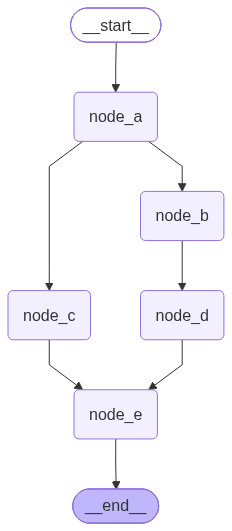

In [1]:
'''这是多分支汇聚中最常见的情况。

LangGraph 的计算图是在一系列超步中完成的，如果能看到每个节点实例运行时的超步编号，则节点执行顺序一目了然。

LangGraph 的节点可以通过名为 config 的有名参数获取运行时配置

config 的元数据中记录了当前节点所在的 SuperStep 序号，可以通过下面的方式获取：
config["metadata"]["langgraph_step"]
'''


from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables import RunnableConfig

from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_a 被触发", cur_step)
    return {}

def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_b 被触发", cur_step)
    return {}

def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_c 被触发", cur_step)
    return {}

def node_d(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_d 被触发", cur_step)
    return {}

def node_e(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_e 被触发", cur_step)
    return {}

builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_b", "node_d")
builder.add_edge(["node_c", "node_d"], "node_e")
'''表示 node_e 需要等待 node_c 和 node_d 两个上游节点全部完成后，才会被触发一次。'''
graph = builder.compile()
graph.invoke({})

from IPython.display import display
display(graph)

2026-10-17 15:09:34.611 | INFO     | __main__:reducer_node:45 - reducer entries: [('hello', 1), ('world', 1), ('hello', 1), ('Atguigu', 1), ('hello', 1), ('LLM', 1)]
2026-10-17 15:09:34.611 | INFO     | __main__:reducer_node:55 - reducer shuffle entries: {'hello': [1, 1, 1], 'world': [1], 'Atguigu': [1], 'LLM': [1]}


{'input_values': ['hello world', 'hello Atguigu', 'hello LLM'], 'entries': [('hello', 1), ('world', 1), ('hello', 1), ('Atguigu', 1), ('hello', 1), ('LLM', 1)], 'word_counts': {'hello': 3, 'world': 1, 'Atguigu': 1, 'LLM': 1}}


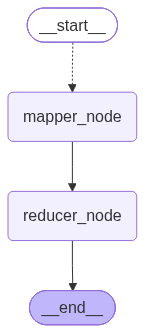

In [2]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from _collections_abc import Sequence
from operator import add

from loguru import logger

class OverAllState(TypedDict):
    input_values: list[str]
    entries: Annotated[list[tuple[str, int]], add]
    word_counts: dict[str, int]

def router_map(state: OverAllState) -> Sequence[Send]:
    input_values = state["input_values"]

    tasks = []
    for input_value in input_values:
        tasks.append(
            Send(
                "mapper_node",
                {"input_value": input_value}
            )
        )

    return tasks

class MaperInputState(TypedDict):
    input_value: str

def mapper_node(state: MaperInputState) -> OverAllState:
    input_value = state["input_value"]
    words = input_value.split(" ") # 分词
    entries = []

    for word in words:
        entries.append((word, 1))

    return {
        "entries": entries
    }

def reducer_node(state: OverAllState) -> OverAllState:
    entries = state["entries"]
    logger.info("reducer entries: {}", entries)

    shuffle_dict = {}

    for k, v in entries:
        if k not in shuffle_dict:
            shuffle_dict[k] = [v]
        else:
            shuffle_dict[k].append(v)

    logger.info("reducer shuffle entries: {}", shuffle_dict)

    reduce_dict = {}

    for k, v in shuffle_dict.items():
        reduce_dict[k] = sum(v)

    return {
        "word_counts": reduce_dict
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("mapper_node", mapper_node)
builder.add_node("reducer_node", reducer_node)
builder.add_conditional_edges(START, router_map, path_map=["mapper_node"])
builder.add_edge("mapper_node", "reducer_node")
builder.add_edge("reducer_node", END)

graph = builder.compile()
word_counts = graph.invoke(
    {"input_values": [
        "hello world",
        "hello Atguigu",
        "hello LLM"
    ]}
)

print(word_counts)

from IPython.display import display
display(graph)

============================== -> ai_res <- ==============================
user_input:  帮我查询杭州当日天气和AI热点
final_answer:  查询完成，结果如下：

## 🌤️ 杭州当日天气
- **天气**：晴朗
- **风向风力**：东南风三级
- **气温**：25~30 ℃

天气不错，适合外出，注意防晒和补水。

## 🤖 AI 领域热点
- **Anthropic 发布 Claude Opus-4.8**，但出现了一个奇怪的现象：通过 API 用中文向它发送"你是谁？"时，**大多数情况下返回的却是"Qwen"或"Deepseek"**（即回答自己是中国的大模型）。这引发了关于模型身份认知、训练数据来源以及中文语料影响的讨论。

> 说明：AI 热点查询前两次因网络波动失败，第三次重试后成功获取。
================================ System Message ================================

如果工具调用失败，必须重新调用直至成功
================================ Human Message =================================

帮我查询杭州当日天气和AI热点
================================== Ai Message ==================================

我会同时查询这两项信息。
Tool Calls:
  get_weather (call_00_mHy94htsVyA3WzHCGp5D5057)
 Call ID: call_00_mHy94htsVyA3WzHCGp5D5057
  Args:
    city: 杭州
  get_news (call_01_YyJt9LHUm8p42YaPStLT4512)
 Call ID: call_01_YyJt9LHUm8p42YaPStLT4512
  Args:
    domain: AI
================================= Tool Message =============

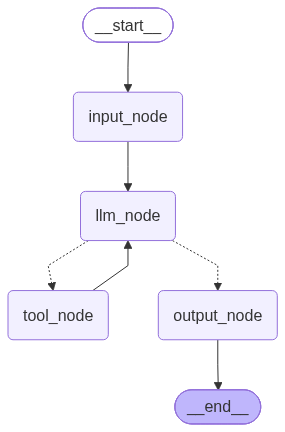

In [3]:
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek

from random import randint
from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

@tool(parse_docstring=True)
def get_weather(city: str="北京"):
    """
    查询指定城市当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气晴朗，东南风三级，气温 25~30 ℃"

@tool(parse_docstring=True)
def get_news(domain: Literal["AI", "食品安全"]):
    """
    查询特定领域的当日热点

    Args:
        domain: 特定领域
    """
    if domain == "AI":
        return "Anthropic 发布了 Claude Opus-4.8，但通过 API 用中文向它发送“你是谁？”时，大多数情况下返回的却是“Qwen”或“Deepseek”。"
    else:
        return "双汇发展子公司猪肉产品被抽检出抗生素超标37.5倍"

tools = [get_weather, get_news]

model_with_tools = model.bind_tools(tools=tools)

class OverAllState(MessagesState):
    user_input: str
    final_answer: str

def input_node(state: OverAllState) ->OverAllState:
    return {
        "messages": [HumanMessage(state["user_input"])],
    }

def llm_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = model_with_tools.invoke(messages)
    return {
        "messages": [ai_msg],
    }

def tool_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = messages[-1]
    tool_calls = ai_msg.tool_calls

    fail_prob = 6 # 失败概率，6表示 60% 概率失败，7 -> 70%，8 -> 80%，依次类推

    for tool_call in tool_calls:
        if tool_call["name"] == "get_weather":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_weather.invoke(tool_call))
        elif tool_call["name"] == "get_news":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_news.invoke(tool_call))
        else:
            messages.append(
                ToolMessage(
                    content="工具名称错误，调用失败，请重试",
                    tool_call_id=tool_call["id"]
                )
            )

    return {
        "messages": messages
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "final_answer": state["messages"][-1].content
    }

def router(state: OverAllState) -> Literal["tool_node", "output_node"]:
    messages = state["messages"]
    lst_msg = messages[-1]

    if lst_msg.tool_calls:
        return "tool_node"
    return "output_node"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("input_node", input_node)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_node("output_node", output_node)

builder.add_edge(START, "input_node")
builder.add_edge("input_node", "llm_node")
builder.add_conditional_edges(
    "llm_node",
    router
)
builder.add_edge("tool_node", "llm_node")
builder.add_edge("output_node", END)

graph = builder.compile()
ai_res = graph.invoke({
    "user_input": "帮我查询杭州当日天气和AI热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})
food_safety_res = graph.invoke({
    "user_input": "帮我查询当日天气和食品安全相关的热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})

print('=' * 30, '-> ai_res <-', '=' * 30)
print("user_input: ", ai_res["user_input"])
print("final_answer: ", ai_res["final_answer"])
for msg in ai_res["messages"]:
    msg.pretty_print()

print('=' * 30, '-> food_safety_res <-', '=' * 30)
print("user_input: ", food_safety_res["user_input"])
print("final_answer: ", food_safety_res["final_answer"])
for msg in food_safety_res["messages"]:
    msg.pretty_print()

from IPython.display import display
display(graph)

In [ ]:
def llm_node(state: OverAllState) -> Command[Literal["tool_node", "output_node"]]:
    ai_msg = model_with_tools.invoke(state["messages"])

    if ai_msg.tool_calls:
        goto = "tool_node"
    else:
        goto = "output_node"

    return Command(
        update={
            "messages": [ai_msg],
        },
        goto=goto,
    )

'''其返回值类型：
Command[Literal["tool_node", "output_node"]]
表明该节点返回的是一个 Command 对象，且 goto 字段的值只能是：
"tool_node"
或 "output_node"
这是静态约束，不会参与运行时校验。主要作用是提升代码可读性、通过静态类型检查，同时帮助 LangGraph 更准确地推断图结构。'''

'''
|            | 静态实现                               | 动态实现                   |
| ---------- | -------------------------------------- | -------------------------- |
| 路由位置   | 路由逻辑在独立的 **`router()`** 函数中 | 路由逻辑写在节点返回值中   |
| 图结构表达 | 显式声明条件边，更直观                 | 控制逻辑更内聚，代码更紧凑 |
| 适合场景   | 路由规则独立、希望图结构更清晰         | 节点执行结果直接决定下一跳 |

两种方式都能实现 **`ReAct`** 循环，本质区别不在于是否能循环，而在于：

> **路由逻辑写在哪里。**

* 基于 **`add_conditional_edges()`** 的静态实现：把控制逻辑放在图结构定义阶段；
* 基于 **`Command(goto=...)`** 的动态实现：把控制逻辑放在节点返回值中。
'''

2026-10-17 16:29:26.366 | INFO     | __main__:loop_node:24 - loop_node, cur_step: 1, remaining_step: 9
2026-10-17 16:29:26.369 | INFO     | __main__:loop_node:24 - loop_node, cur_step: 2, remaining_step: 8
2026-10-17 16:29:26.370 | INFO     | __main__:loop_node:24 - loop_node, cur_step: 3, remaining_step: 7
2026-10-17 16:29:26.370 | INFO     | __main__:loop_node:24 - loop_node, cur_step: 4, remaining_step: 6
2026-10-17 16:29:26.371 | INFO     | __main__:loop_node:24 - loop_node, cur_step: 5, remaining_step: 5
2026-10-17 16:29:26.372 | INFO     | __main__:loop_node:24 - loop_node, cur_step: 6, remaining_step: 4
2026-10-17 16:29:26.372 | INFO     | __main__:loop_node:24 - loop_node, cur_step: 7, remaining_step: 3
2026-10-17 16:29:26.373 | INFO     | __main__:loop_node:24 - loop_node, cur_step: 8, remaining_step: 2
2026-10-17 16:29:26.373 | INFO     | __main__:router:29 - 当前可用超步：2，已不足2步，终止运行图


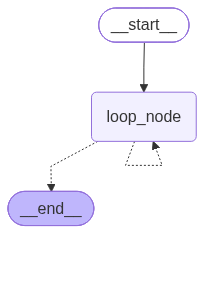

In [4]:
'''
RemainingSteps 是 LangGraph 提供的特殊托管值，表示剩余可用步数，由运行时维护。

LangGraph 运行时会根据当前步数和 recursion_limit 计算剩余步数，并填充到 RemainingSteps 类型的状态字段中。开发者可以在状态中声明一个 RemainingSteps 类型的字段，来获取剩余可用步数。

借助 RemainingSteps，开发者可以在图内部提前判断剩余步数是否充足，并根据剩余步数动态路由。例如，当剩余步数较少时，不再继续循环，而是路由到 END 或兜底节点，从而让运行图正常结束。

这种方式是在达到递归限制之前主动处理，因此称为 主动方法（Proactive Approach）。

'''
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.managed import RemainingSteps
from langchain_core.runnables.config import RunnableConfig

from loguru import logger

class OverAllState(TypedDict):
    remaining_steps: RemainingSteps

def loop_node(state: OverAllState, config: RunnableConfig) -> OverAllState:
    cur_step = config["metadata"]["langgraph_step"]
    remaining_steps = state["remaining_steps"]
    logger.info("loop_node, cur_step: {}, remaining_step: {}", cur_step, remaining_steps)

def router(state: OverAllState) -> Literal["loop_node", END]:
    remaining_steps = state["remaining_steps"]
    if remaining_steps < 3:
        logger.info("当前可用超步：{}，已不足2步，终止运行图", remaining_steps)
        return END
    return "loop_node"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("loop_node", loop_node)
builder.add_edge(START, "loop_node")
builder.add_conditional_edges("loop_node", router)

graph = builder.compile()
graph.invoke({}, config={"recursion_limit": 10})

from IPython.display import display
display(graph)